### Imports

In [113]:
from PIL import Image, ImageDraw, ImageFont
import cv2
import matplotlib.pyplot as plt
import numpy as np
import base64
import io
from enum import Enum
import requests
from ollama import Client
from pydantic import BaseModel
from typing import List
import json
from typing import List, Literal, Annotated
from pydantic import Field

### Variables

In [75]:
frames_list = [] # initial frames of imported video
frames_with_grid = []    # frames with grid and numbers
frames_converted_base64 = []    # frames converted in base64
GRID_ROWS = 3
GRID_COLS = 3
FPS = 10

class Path(Enum):
    AMAZON_BOX_CENTER = "data/video1.mp4"
    INDIAN_OFFICE = "data/video.mp4"
    CONSEGNA_BARTOLINI = "data/consegna_bartolini.mp4"


video_path= Path.CONSEGNA_BARTOLINI.value

Prima passare il video a opencv per tracciare il movimento delle persone? idk

###  Get video frames

In [76]:
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print("Error opening video stream or file")
else:
    print("Extraction of frames...")

    # Obtain the original video fps
    original_fps = cap.get(cv2.CAP_PROP_FPS)

    # calculate the interval between frames
    frame_interval = int(original_fps / FPS)

    frame_count = 0
    while True:
        ret, frame = cap.read()

        if not ret:
            break

        # extract the frames
        if frame_count % frame_interval == 0:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames_list.append(frame_rgb)

        frame_count += 1

    cap.release()
    print(f"Completed! Extracted {len(frames_list)} frames at {FPS} FPS from original {original_fps:.2f} FPS")


Extraction of frames...
Completed! Extracted 45 frames at 10 FPS from original 30.00 FPS


### For each frame insert a grid to help the vllm

225


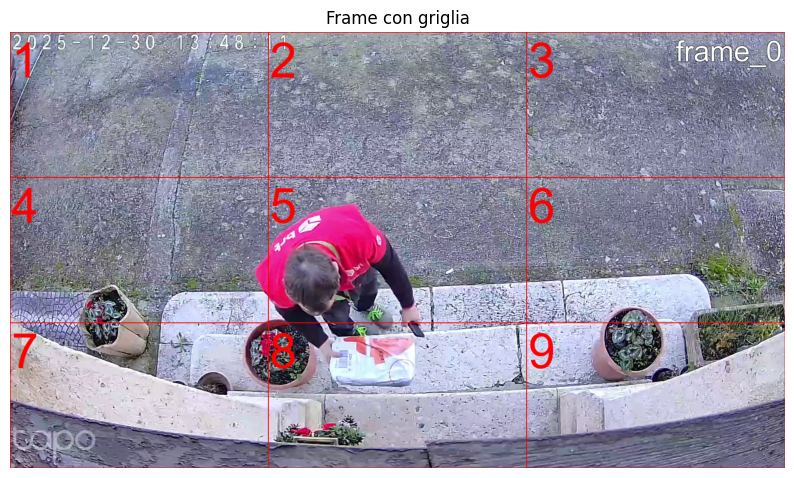

In [159]:
for idx, frame in enumerate(frames_list):
    # 1. Load images
    # Convert the frame (numpy.ndarray RGB) to PIL Image
    img_pil = Image.fromarray(frame)

    draw = ImageDraw.Draw(img_pil)
    width, height = img_pil.size

    # 2. Calculate cell size
    step_x = width / GRID_COLS
    step_y = height / GRID_ROWS

    # 3. Set a font (optional, use the system font if not available)
    # The larger the image, the larger the font size should be
    font_size = int(min(step_x, step_y) / 3)
    try:
        font = ImageFont.truetype("arial.ttf", font_size)
    except:
        font = ImageFont.load_default()

    # 4. Draw frame number in top right
    frame_text = f"frame_{idx}"
    # Use a smaller font size (1/5 of cell size instead of 1/3)
    frame_font_size = int(min(step_x, step_y) / 5)
    try:
        frame_font = ImageFont.truetype("arial.ttf", frame_font_size)
    except:
        frame_font = ImageFont.load_default()

    text_bbox = draw.textbbox((0, 0), frame_text, font=frame_font)
    text_width = text_bbox[2] - text_bbox[0]
    text_x = width - text_width - 10

    # Draw text with black outline
    for offset in [(-1, -1), (-1, 1), (1, -1), (1, 1), (-1, 0), (1, 0), (0, -1), (0, 1)]:
        draw.text((text_x + offset[0], 10 + offset[1]), frame_text, fill="black", font=frame_font)

    # Draw white text on top
    draw.text((text_x, 10), frame_text, fill="white", font=frame_font)

    # 5. Draw rows and columns
    count = 1
    for i in range(GRID_ROWS):
        for j in range(GRID_COLS):
            # Cell coordinates
            left = j * step_x
            top = i * step_y
            right = (j + 1) * step_x
            bottom = (i + 1) * step_y

            # Draw rectangle (cell border)
            draw.rectangle([left, top, right, bottom], outline="red", width=2)

            # Draw the number in the centre of the cell
            testo = str(count)
            # Calculating position to centre text
            draw.text((left + 5, top + 5), testo, fill="red", font=font)

            count += 1

    frames_with_grid.append(img_pil)

print(len(frames_with_grid))
if not frames_with_grid:
    print("Nessun frame disponibile")
else:
    first = frames_with_grid[0]
    plt.figure(figsize=(10, 6))
    # If it is a PIL image we convert it to an array, otherwise we display it directly
    img = np.asarray(first) if hasattr(first, "size") else first
    plt.imshow(img)
    plt.axis('off')
    plt.title("Frame con griglia")
    plt.show()



Transform the image in base 64

In [78]:
for frame_grid in frames_with_grid:
    buf = io.BytesIO()
    # assicurarsi che l'immagine sia in RGB e salvarla in un formato (PNG)
    frame_grid.convert("RGB").save(buf, format="PNG")
    img_bytes = buf.getvalue()
    # opzionale: ottenere una stringa base64 invece di bytes
    img_b64 = base64.b64encode(img_bytes).decode("ascii")
    frames_converted_base64.append(img_b64)

print(len(frames_converted_base64))
print(frames_converted_base64[0][:100] + "...")

45
iVBORw0KGgoAAAANSUhEUgAACgAAAAWgCAIAAAAdYo2IAAEAAElEQVR4nOz9CZRt51Weja7d9/2uvur0OmqtY0mWLdmWscFgDNgB...


### Make API call

Enum for traking all models

In [114]:
class Models(Enum):
    qwen3_2 = "qwen3-vl:2b"
    qwen3_4 = "qwen3-vl:4b"
    qwen3_8 = "qwen3-vl:8b"
    gemma3_4 = "gemma3:4b"
    gemma3_12 = "gemma3:12b"            # more or less 1 min
    mistral_8 = "ministral-3:8b"
    mistral_14 = "ministral-3:14b"      # 1min or more but less 2 min

Model infos

In [156]:
PROMPT = """you are a video surveillance VLM, analyze the image I sent you and reply only with a json representation of what is in each grid cell.
Each cell is numbered in the bottom right corner of the cell, they're numbered from left to right, from top to bottom.
Insert a box or any generic object in the representation only if it is interacting, or you think it will be interacting, with other objects or people.
If an element is present in more than one cell, insert it in one single cell only.
If a person is present in more than one cell, insert it in one single cell only.
In a cell you can insert only a person that is not present in other cells.
Each represented box should be labeled with a number.
Only consider foreground elements, not the surrounding environment.
The video is taken from above the ground so take attention to don't confuse other object with people.
Print the output as a json for all 9 cell blocks"""

API_URL = "http://catgottzqq.ddns.net:63452"

MODEL = Models.gemma3_12.value

Strucured output classes

In [155]:
class CellContent(BaseModel):
    people: Literal['person_1', 'none']
    objects: Literal['Box', 'Tool', 'Unknown', 'none']
    reasoning: str = Field(description="Explain what you see in this cell and why you classified the people and objects this way. Be specific about positions, actions, and interactions.")

class GridAnalysis(BaseModel):
    cell_1: CellContent
    cell_2: CellContent
    cell_3: CellContent
    cell_4: CellContent
    cell_5: CellContent
    cell_6: CellContent
    cell_7: CellContent
    cell_8: CellContent
    cell_9: CellContent

Make request

##### Normal http request

In [82]:
# payload = {
#     "model": MODEL,
#     "prompt": PROMPT,
#     "stream": False,
#     "images": [frames_converted_base64[0]],
#     "format": "json",
# }
# headers = {
#     "Content-Type": "application/json",
# }
#
# response = requests.request("POST", API_URL, json=payload, headers=headers)
#
# print(response.text)

##### API call with ollama Client

In [160]:
client = Client(
    host=API_URL,
    headers={'Content-Type': 'application/json'}
)
response = client.chat(
    model=MODEL,
    messages=[
        {
            'role': 'user',
            'content': PROMPT,
            'images': [frames_converted_base64[0]],
        }
    ],
    stream=False,
    options={'temperature': 0.8},
    format=GridAnalysis.model_json_schema(),
)

response_content = response.message.content
print(json.dumps(json.loads(response_content), indent=2))

#Save into a json file
with open('response.json', 'w', encoding='utf-8') as f:
    json.dump(json.loads(response_content), f, indent=2, ensure_ascii=False)

print("\nJSON saved in 'response.json'")


{
  "cell_1": {
    "people": "none",
    "objects": "none",
    "reasoning": "The cell is empty, showing a patch of ground."
  },
  "cell_2": {
    "people": "none",
    "objects": "none",
    "reasoning": "The cell is empty, showing a patch of ground."
  },
  "cell_3": {
    "people": "none",
    "objects": "none",
    "reasoning": "The cell is empty, showing a patch of ground."
  },
  "cell_4": {
    "people": "none",
    "objects": "none",
    "reasoning": "The cell is empty, showing a patch of ground."
  },
  "cell_5": {
    "people": "none",
    "objects": "none",
    "reasoning": "The cell is empty, showing a patch of ground."
  },
  "cell_6": {
    "people": "none",
    "objects": "none",
    "reasoning": "The cell is empty, showing a patch of ground."
  },
  "cell_7": {
    "people": "none",
    "objects": "none",
    "reasoning": "The cell is empty, showing a patch of ground."
  },
  "cell_8": {
    "people": "none",
    "objects": "none",
    "reasoning": "The cell is empty,